In [1]:
import pandas as pd  
import numpy as np




In [2]:
import sys
!{sys.executable} -m pip install pandas numpy

In [3]:
#At--> temperature
#v --> vaccum
#AP--> pressure
#RH--> humidity
#PE __>produced energy


In [3]:
df = pd.read_csv("powerplant_data.csv")

In [4]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [5]:
df.isnull().sum()


AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE" , axis = 1)
y = df["PE"]

In [7]:
X.head()

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


In [8]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X , y , test_size = 0.2 , random_state = 42)

In [10]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
df.shape

(9568, 5)

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [12]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled ,dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values , dtype = torch.float32).view(-1 , 1)
X_test_tensor = torch.tensor(X_test_scaled , dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values , dtype = torch.float32).view(-1 , 1)

In [13]:
 from torch.utils.data import TensorDataset , DataLoader
train_dataset = TensorDataset(X_train_tensor , y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [14]:
train_loader = DataLoader(train_dataset , batch_size = 32 , shuffle = True)
test_loader = DataLoader(test_dataset , batch_size = 32)

### DeepLearning

In [ ]:
import torch
import torch.nn as nn

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output layer
            nn.Linear(6, 1)
        )

    def forward(self, x):
        return self.model(x)


In [ ]:
import torch.optim as optim

model = ANN()

#loss , optmizer
criterion = nn.MSELoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)



In [19]:

# Train the ANN model

train_losses = []
valid_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(xb)

        # Compute loss
        loss = criterion(outputs, yb)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item()

    # Average training loss for this epoch
    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs, yb)
            running_val_loss += loss.item()

    # Average validation loss
    epoch_val_loss = running_val_loss / len(test_loader)
    valid_losses.append(epoch_val_loss)

    # Print progress
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Train Loss: {epoch_train_loss:.4f}, "
            f"Validation Loss: {epoch_val_loss:.4f}"
        )

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), "best_model.pt")

    
     


Epoch [10/100], Train Loss: 4515.2964, Validation Loss: 3850.4174
Epoch [20/100], Train Loss: 442.7109, Validation Loss: 415.9929
Epoch [30/100], Train Loss: 31.4096, Validation Loss: 29.9523
Epoch [40/100], Train Loss: 21.7150, Validation Loss: 20.9365
Epoch [50/100], Train Loss: 21.7049, Validation Loss: 19.8540
Epoch [60/100], Train Loss: 21.5269, Validation Loss: 19.9970
Epoch [70/100], Train Loss: 21.5201, Validation Loss: 19.8251
Epoch [80/100], Train Loss: 21.4660, Validation Loss: 20.5227
Epoch [90/100], Train Loss: 21.5449, Validation Loss: 19.6230
Epoch [100/100], Train Loss: 21.5805, Validation Loss: 19.6869


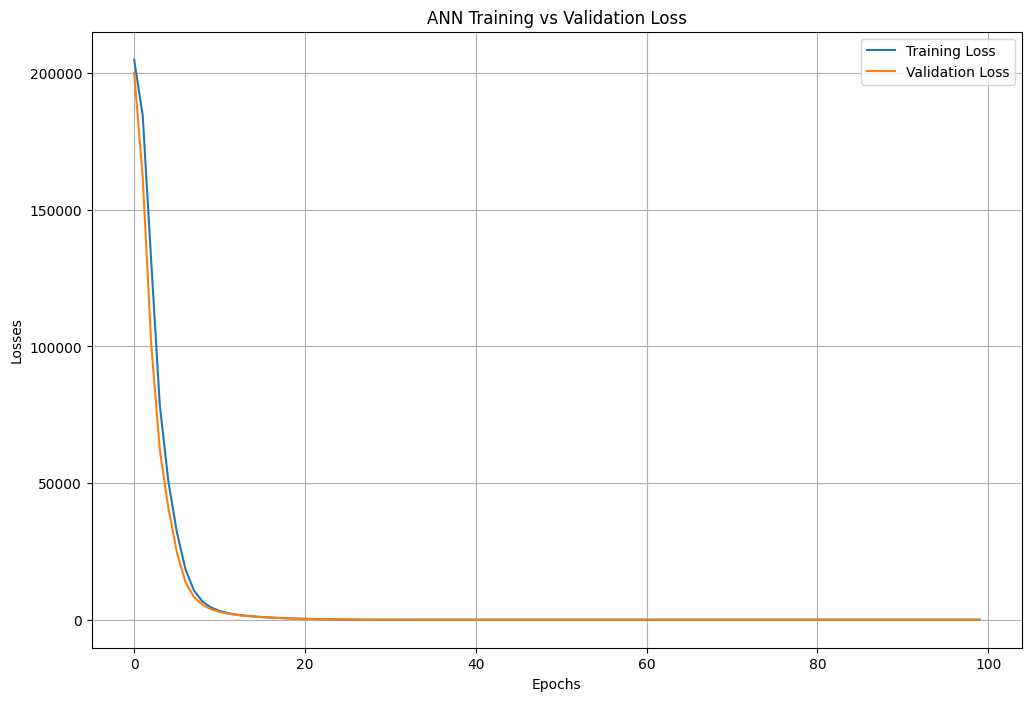

In [20]:

import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": valid_losses
})

plt.figure(figsize=(12, 8))

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.title("ANN Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


In [21]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [22]:
# loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [23]:
#evaluation
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds , y_train_tensor)
    test_mse_loss = criterion(test_preds , y_test_tensor)
    
print("Training MSE :" , train_mse_loss.item())   
print("Testing MSE:" , test_mse_loss.item())
    

Training MSE : 21.081989288330078
Testing MSE: 19.63237762451172


In [24]:
from sklearn.metrics import r2_score

print("r^2 score = " , r2_score(y_test, test_preds))


r^2 score =  0.9313899040863461


In [ ]:
predicted_df = pd.DataFrame(
    test_preds.detach().cpu().numpy().reshape(-1),
    columns=["Predicted Values"]
)

actual_df = pd.DataFrame(
    y_test,
    columns=["Actual Values"]
)


pd.concat([predicted_df, actual_df], axis=1)

